# Process simulation

A flowsheet in Python: the palette, a document, and the envelope every edit returns. The
document is TOML; `Session` opens it with the palette compiled into the package, so this
notebook reads no repository file.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import azoth
import azoth.process

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.alpha": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "lines.linewidth": 2.0,
        "font.size": 9,
        "figure.figsize": (6.4, 3.4),
    }
)

q = azoth.ureg.Quantity

## The palette

`forms()` is the declaration behind every unit-operation window: the ports, the parameters and
the model's own bounds. It is data, so it can be a table.

In [2]:
forms = azoth.process.forms()
palette = pd.DataFrame(
    [
        {
            "id": form["id"],
            "family": form["family"],
            "runnable": form["runnable"],
            "parameters": len(form["parameters"]),
            "ports": len(form["ports"]),
        }
        for form in forms
    ]
)
print(f"{len(palette)} entries")
palette.head(10)

31 entries


,id,family,runnable,parameters,ports
0,unit_ops.absorption_column,column,True,18,4
1,unit_ops.distillation_column,column,True,51,3
2,unit_ops.packed_column,column,True,24,3
3,unit_ops.rate_based_packed_column,column,True,11,4
4,unit_ops.shortcut_distillation_column,column,True,7,3
5,unit_ops.simple_absorber,column,False,0,4
6,unit_ops.stripping_column,column,True,18,4
7,unit_ops.heat_exchanger,heat_exchanger,True,7,4
8,unit_ops.map_turbo_expander_compressor,machine,True,8,4
9,unit_ops.turbo_expander_compressor,machine,True,14,4


## A self-contained document

The demo flowsheet: a feed, a mixer, a pump, a heater and a separator, with the separator
liquid recycled to the mixer. The `[layout]` block is where an editor draws the nodes; the run
ignores it.

In [3]:
DEMO = r"""id = "flowsheets.demo"
name = "Feed, pump, heat, separate, recycle"

products = ["vapour_product"]

[[inputs]]
name = "feed_1"
components = ["methane", "n-butane"]
n = 1.0
z = [0.9, 0.1]
P = 5.0e5
T = 300.0

[[instances]]
id = "mix1"
unit = "unit_ops.mixer"

[[instances]]
id = "p1"
unit = "unit_ops.pump"
[instances.parameters]
outlet_pressure = 2.0e6
isentropic_efficiency = 0.75

[[instances]]
id = "hx1"
unit = "unit_ops.heater"
[instances.parameters]
outlet_temperature = 320.0

[[instances]]
id = "sep1"
unit = "unit_ops.separator"
[instances.parameters]
pressure_drop = 5.0e4
gas_in_liquid = 0.0

[[connections]]
from = "feed_1"
to = "mix1.feed[0]"

[[connections]]
from = "mix1.product"
to = "p1.inlet"

[[connections]]
from = "p1.outlet"
to = "hx1.inlet"

[[connections]]
from = "hx1.outlet"
to = "sep1.feed"

[[connections]]
from = "sep1.vapour"
to = "vapour_product"

[[recycles]]
stream = "recycle_1"
from = "sep1.liquid"
to = "mix1.feed[1]"

# Where an editor draws each node. Nothing in the run reads it - the checker ignores it and the
# executor never sees it - and its position here, after the arrays of tables, is the only order
# TOML lets a writer emit. A flowsheet without a `[layout]` derives a deterministic one instead.
[layout.inputs]
feed_1 = [0.0, 60.0]

[layout.instances]
mix1 = [240.0, 60.0]
p1 = [480.0, 60.0]
hx1 = [720.0, 60.0]
sep1 = [960.0, 60.0]

[layout.products]
vapour_product = [1200.0, 0.0]
"""
print(DEMO[:400] + "\n...")

id = "flowsheets.demo"
name = "Feed, pump, heat, separate, recycle"

products = ["vapour_product"]

[[inputs]]
name = "feed_1"
components = ["methane", "n-butane"]
n = 1.0
z = [0.9, 0.1]
P = 5.0e5
T = 300.0

[[instances]]
id = "mix1"
unit = "unit_ops.mixer"

[[instances]]
id = "p1"
unit = "unit_ops.pump"
[instances.parameters]
outlet_pressure = 2.0e6
isentropic_efficiency = 0.75

[[instances]]
id 
...


## Run it

`Session.run()` returns the whole envelope: whether the document checks, whether the values are
stale, the graph, the diagnostics, and the run's report. A run that fails is reported in
`run_error`, not raised.

In [4]:
session = azoth.process.Session(DEMO)
env = session.run()

print("ok:", env["ok"], "| dirty:", env["dirty"], "| order:", env["execution_order"])
print("run error:", env["run_error"])
print("converged:", env["session"]["converged"], "| passes:", env["session"]["iterations"])
print("paths:", len(env["paths"]))

ok: True | dirty: False | order: insertion
run error: None
converged: True | passes: 2
paths: 43


## The streams

Every stream is a record with `n`, `z`, `P`, `T`, `h`, and where the library can weigh the
fluid, `mass_flow`, `molar_mass` and `vapour_fraction`. Scalar values are in SI.

In [5]:
def si(record: dict, key: str) -> float | None:
    value = record[key]
    return None if value is None else value["magnitude_si"]


streams = pd.DataFrame(
    [
        {
            "stream": name,
            "n (mol/s)": si(record, "n"),
            "P (bar)": si(record, "P") / 1e5,
            "T (K)": si(record, "T"),
            "h (kJ/mol)": si(record, "h") / 1e3,
            "vapour fraction": record["vapour_fraction"],
        }
        for name, record in env["session"]["streams"].items()
    ]
)
streams

,stream,n (mol/s),P (bar),T (K),h (kJ/mol),vapour fraction
0,feed_1,1.0,5.0,300.000000,0.978693,1.0
1,hx1.outlet,1.0,20.0,320.000000,1.482796,1.0
2,mix1.product,1.0,5.0,300.000000,0.978693,1.0
3,p1.outlet,1.0,20.0,416.023332,6.151645,1.0
4,sep1.liquid,0.0,19.5,320.000000,1.495086,0.0
5,sep1.vapour,1.0,19.5,320.000000,1.495086,1.0
6,vapour_product,1.0,19.5,320.000000,1.495086,1.0


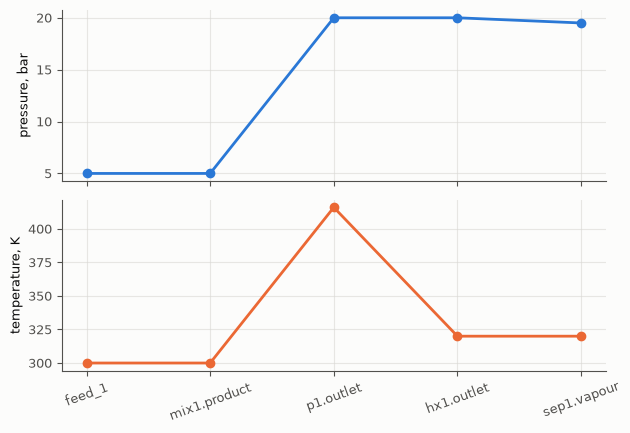

In [6]:
path = ["feed_1", "mix1.product", "p1.outlet", "hx1.outlet", "sep1.vapour"]
pressure = [si(env["session"]["streams"][name], "P") / 1e5 for name in path]
temperature = [si(env["session"]["streams"][name], "T") for name in path]

fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(6.4, 4.4))
top.plot(path, pressure, "o-", color=PALETTE[0])
top.set_ylabel("pressure, bar")
bottom.plot(path, temperature, "o-", color=PALETTE[1])
bottom.set_ylabel("temperature, K")
bottom.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
plt.close(fig)

## Recycle tears

The loop is solved by fixed point. A tear is `active` when the recycled stream carries enough
flow to matter; at the demo's 320 K the liquid is gone, so the recycle is inactive and the run
is one pass.

In [7]:
for tear in env["session"]["tears"]:
    print(tear)

{'stream': 'recycle_1', 'iterations': 1, 'solved': True, 'active': False, 'residuals': {'flow': 0.0, 'composition': 0.0, 'temperature': 0.0, 'pressure': 0.0}}


## A sweep that turns the recycle on

Dropping the heater outlet temperature makes liquid at the separator. The recycle becomes
active, the mixed feed exceeds the fresh feed, and the tear is converged rather than assumed.

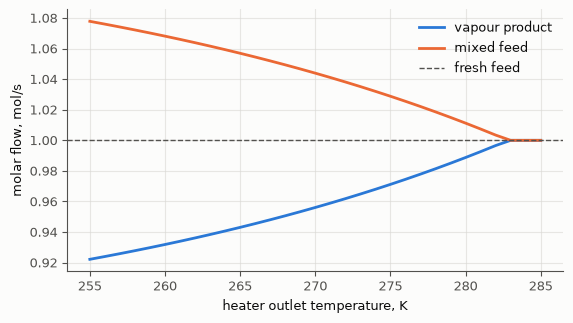

recycle active from 255 to 282 K


In [8]:
temperatures = np.linspace(255.0, 285.0, 31)
vapour, mixed, active = [], [], []
for temperature in temperatures:
    session.apply(
        {
            "command": "set_parameter",
            "instance": "hx1",
            "name": "outlet_temperature",
            "value": float(temperature),
        }
    )
    report = session.run()["session"]
    vapour.append(si(report["streams"]["sep1.vapour"], "n"))
    mixed.append(si(report["streams"]["mix1.product"], "n"))
    active.append(report["tears"][0]["active"])

fig, ax = plt.subplots()
ax.plot(temperatures, vapour, color=PALETTE[0], label="vapour product")
ax.plot(temperatures, mixed, color=PALETTE[1], label="mixed feed")
ax.axhline(1.0, color=MUTED, linestyle="--", linewidth=1.0, label="fresh feed")
ax.set_xlabel("heater outlet temperature, K")
ax.set_ylabel("molar flow, mol/s")
ax.legend(frameon=False)
plt.show()
plt.close(fig)

on = [float(t) for t, flag in zip(temperatures, active, strict=True) if flag]
if on:
    print(f"recycle active from {min(on):.0f} to {max(on):.0f} K")
else:
    print("recycle inactive across the sweep")

## An edit, then a run

`apply()` re-checks the document and marks the values stale; it does not pay the physics. A
`run()` afterwards returns values that belong to the edited document.

In [9]:
session.apply(
    {
        "command": "set_parameter",
        "instance": "hx1",
        "name": "outlet_temperature",
        "value": 320.0,
    }
)
env = session.apply(
    {
        "command": "set_parameter",
        "instance": "p1",
        "name": "outlet_pressure",
        "value": 4.0e6,
    }
)
print("ok:", env["ok"], "| dirty:", env["dirty"])

env = session.run()
print("pump outlet:", session.value("p1.outlet.P"), "Pa")
print("heater duty:", env["session"]["results"]["hx1"]["outlet_duty"])

ok: True | dirty: True
pump outlet: 4000000.0 Pa
heater duty: {'magnitude_si': -8267.733652392948, 'unit': 'W'}


## A unit operation called directly

The same pump is a function, so a single machine can be checked without a document. `power` is
a result field; the flowsheet's `results` map carries only values that are not already on an
outlet stream.

In [10]:
pump = azoth.process.pump(
    ["methane", "n-butane"],
    q(1.0, "mol/s"),
    [0.9, 0.1],
    q(5.0e5, "Pa"),
    q(300.0, "K"),
    0.75,
    q(4.0e6, "Pa"),
)
print("power:", pump.power.to("kW"))
print("head:", pump.head.to("m"))
print("warnings:", [warning.code.value for warning in pump.warnings])

power: 8.275488433353516 kilowatt
head: 41670.28653302008 meter
warnings: ['RANGE_CHECK_SKIPPED']


## The wheel-specific pitfall

`run_flowsheet` and `validate` take a real `palette_dir` string, defaulting to `specs/unit_ops`
in a checkout. The wheel does not ship `specs/`, so from an installed package use
`Session` (or pass a palette directory), which opens the palette compiled into the extension.

## Next

- [Python scripting and Jupyter](https://patrickmockridge.github.io/azoth/manual/using/python.html)
- [The middleware](https://patrickmockridge.github.io/azoth/manual/architecture/middleware.html)
  describes the envelope, the command model and the doors a front end uses.